In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
df=pd.read_csv('/content/breast_cancer.csv')

In [ ]:
df.head()

,Clump Thickness,Uniformity of Cell Size,Uniformity of Cell Shape,Marginal Adhesion,Single Epithelial Cell Size,Bare Nuclei,Bland Chromatin,Normal Nucleoli,Mitoses,Class
0,5,1,1,1,2,1,3,1,1,2
1,5,4,4,5,7,10,3,2,1,2
2,3,1,1,1,2,2,3,1,1,2
3,6,8,8,1,3,4,3,7,1,2
4,4,1,1,3,2,1,3,1,1,2


In [ ]:
df.isnull().sum()


,0
Clump Thickness,0
Uniformity of Cell Size,0
Uniformity of Cell Shape,0
Marginal Adhesion,0
Single Epithelial Cell Size,0
Bare Nuclei,0
Bland Chromatin,0
Normal Nucleoli,0
Mitoses,0
Class,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 683 entries, 0 to 682
Data columns (total 10 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   Clump Thickness              683 non-null    int64
 1   Uniformity of Cell Size      683 non-null    int64
 2   Uniformity of Cell Shape     683 non-null    int64
 3   Marginal Adhesion            683 non-null    int64
 4   Single Epithelial Cell Size  683 non-null    int64
 5   Bare Nuclei                  683 non-null    int64
 6   Bland Chromatin              683 non-null    int64
 7   Normal Nucleoli              683 non-null    int64
 8   Mitoses                      683 non-null    int64
 9   Class                        683 non-null    int64
dtypes: int64(10)
memory usage: 53.5 KB


In [ ]:
df["Class"].value_counts().to_frame()

,count
Class,
2,444
4,239


In [ ]:
df.describe()

,Clump Thickness,Uniformity of Cell Size,Uniformity of Cell Shape,Marginal Adhesion,Single Epithelial Cell Size,Bare Nuclei,Bland Chromatin,Normal Nucleoli,Mitoses,Class
count,683.000000,683.000000,683.000000,683.000000,683.000000,683.000000,683.000000,683.000000,683.000000,683.000000
mean,4.442167,3.150805,3.215227,2.830161,3.234261,3.544656,3.445095,2.869693,1.603221,2.699854
std,2.820761,3.065145,2.988581,2.864562,2.223085,3.643857,2.449697,3.052666,1.732674,0.954592
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,2.000000
25%,2.000000,1.000000,1.000000,1.000000,2.000000,1.000000,2.000000,1.000000,1.000000,2.000000
50%,4.000000,1.000000,1.000000,1.000000,2.000000,1.000000,3.000000,1.000000,1.000000,2.000000
75%,6.000000,5.000000,5.000000,4.000000,4.000000,6.000000,5.000000,4.000000,1.000000,4.000000
max,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,4.000000


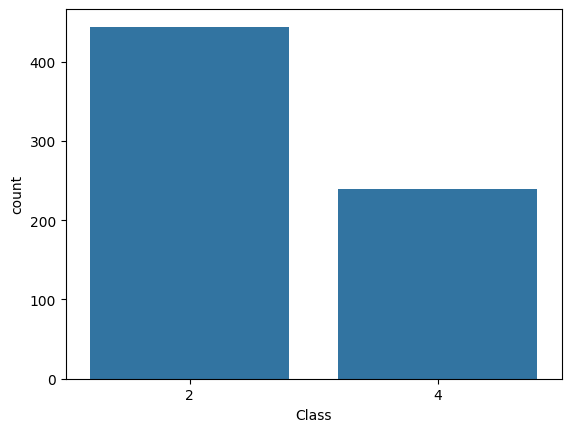

In [ ]:
sns.countplot(data=df,x="Class")
plt.show()

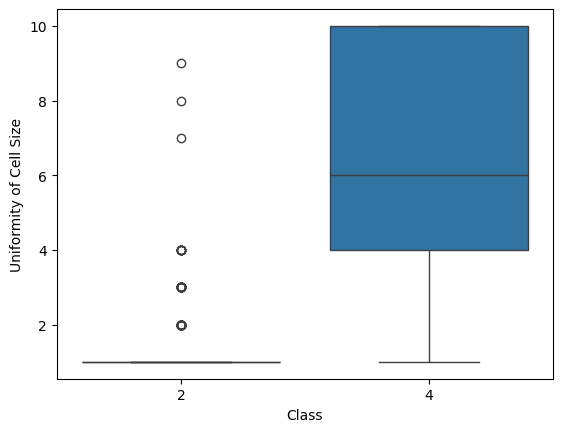

In [ ]:
sns.boxplot(data=df,x="Class",y="Uniformity of Cell Size")
plt.show()


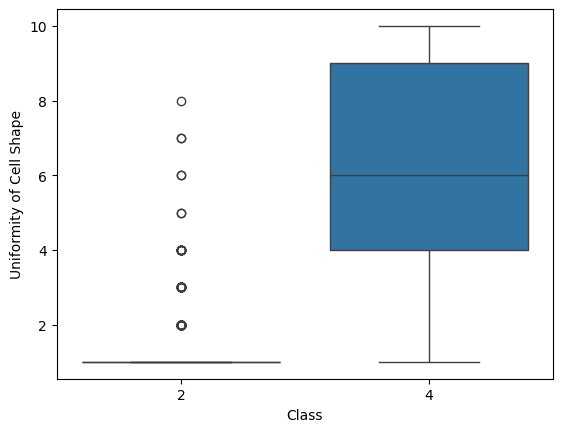

In [ ]:
sns.boxplot(data=df,x="Class",y="Uniformity of Cell Shape")
plt.show()

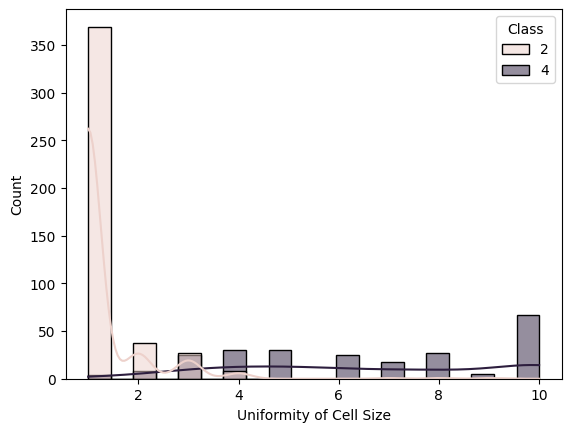

In [ ]:
sns.histplot(data=df,x="Uniformity of Cell Size",hue="Class",kde=True,bins=20)
plt.show()

In [ ]:
##2 = Benign (jinak)

##4 = Malignant (ganas)

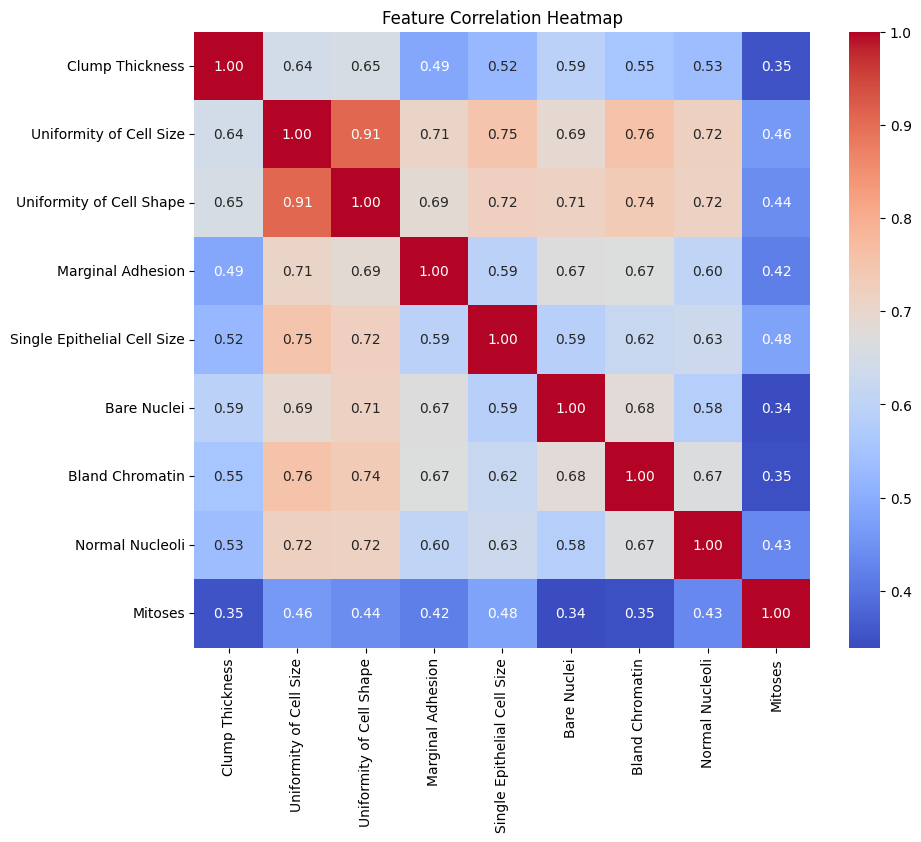

In [ ]:

plt.figure(figsize=(10,8))
corr = df.drop("Class", axis=1).corr()

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    square=True
)
plt.title("Feature Correlation Heatmap")
plt.show()

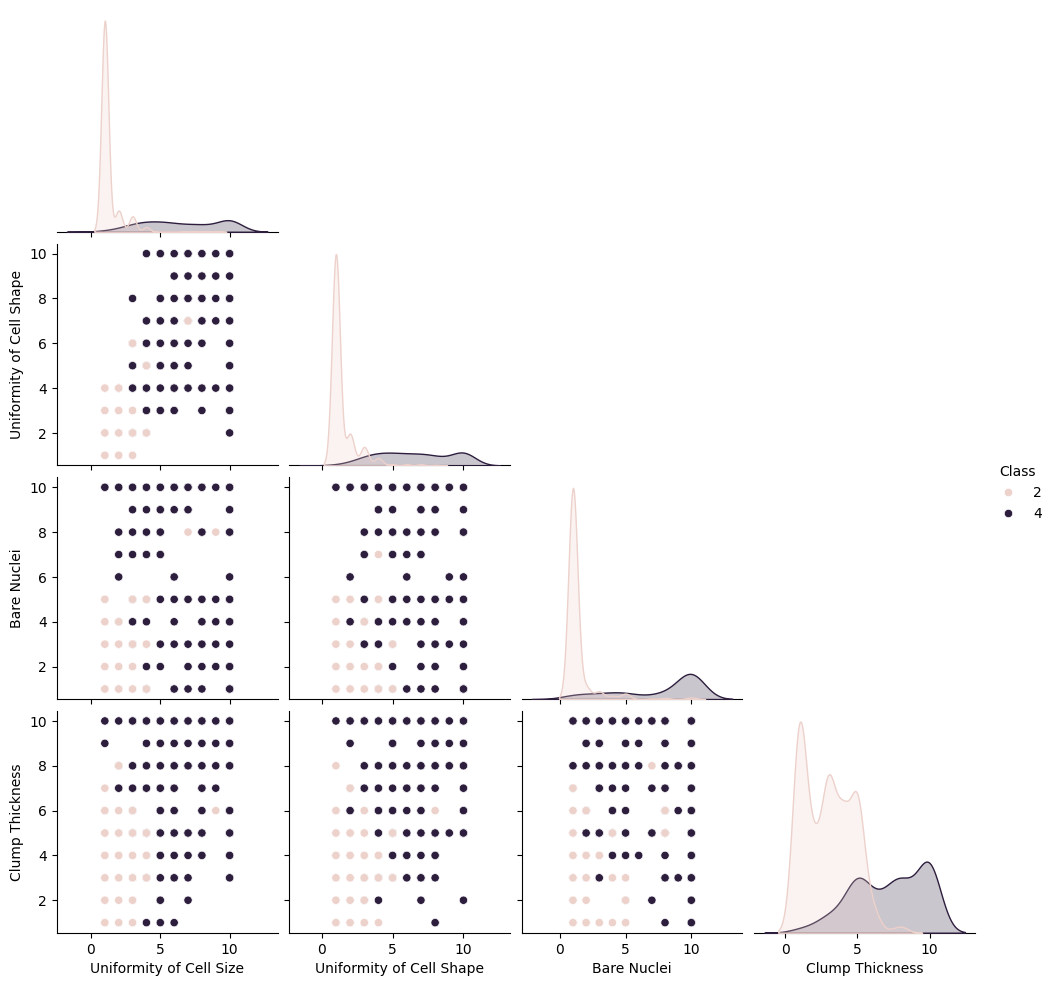

In [ ]:
selected_features = [
    "Uniformity of Cell Size",
    "Uniformity of Cell Shape",
    "Bare Nuclei",
    "Clump Thickness",
    "Class"
]

sns.pairplot(
    df[selected_features],
    hue="Class",
    corner=True
)
plt.show()

In [ ]:
from sklearn.preprocessing import StandardScaler

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
X=df.drop("Class",axis=1)
y=df["Class"]

In [ ]:
X_train,X_test,y_train,y_test=train_test_split(X , y ,test_size=0.20, random_state=15)

In [ ]:
scaler=StandardScaler()

In [ ]:
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report,roc_auc_score

In [ ]:
rdm=RandomForestClassifier()

In [ ]:
rdm.fit(X_train_scaled,y_train)

RandomForestClassifier()

In [ ]:
y_pred=rdm.predict(X_test_scaled)

In [ ]:
print("acc : ",accuracy_score(y_test,y_pred))
print("conf : ",confusion_matrix(y_test,y_pred))
print("class : ",classification_report(y_test,y_pred))
print("roc : ",roc_auc_score(y_test,y_pred))
print("-----------------------------------")
print("\n")

acc :  0.9708029197080292
conf :  [[79  2]
 [ 2 54]]
class :                precision    recall  f1-score   support

           2       0.98      0.98      0.98        81
           4       0.96      0.96      0.96        56

    accuracy                           0.97       137
   macro avg       0.97      0.97      0.97       137
weighted avg       0.97      0.97      0.97       137

roc :  0.9697971781305115
-----------------------------------


